# Lights Out · Phase 2 first answers

A first number for each of the 12 questions, from the gold tables (`02_pipeline/run.py` builds them).
These are first answers: Phase 3 adds the forecast, Phase 4 the full driver split and what-if, and every number
goes through the review checklist before anything is published.

Conventions: load shed is PGCB's grid-level figure. True demand = generation + load shed. Yearly comparisons count
hours 01:00 to 23:00 only, because the downloaded data has no 00:00 readings before March 2026.

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
from pathlib import Path
DB = Path('../01_data/processed/lights_out.duckdb')
con = duckdb.connect(str(DB), read_only=True)
q = lambda s: con.sql(s).df()
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
OAT, CARD, GREEN, GREEN2, OCHRE, TOMATO, SLATE, INK, GRID = '#EEE5D4','#F7F1E6','#1D4A35','#3B8A60','#B87318','#F2462E','#7D8D99','#16382A','#E6DCC8'
plt.rcParams.update({'figure.facecolor': CARD, 'axes.facecolor': CARD, 'axes.edgecolor': GRID, 'axes.labelcolor': INK,
    'xtick.color': '#4F5E52', 'ytick.color': '#4F5E52', 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10.5, 'axes.titlesize': 13,
    'axes.titleweight': 'bold', 'axes.titlecolor': GREEN, 'axes.titlelocation': 'left', 'figure.dpi': 110})
A = {}   # one-line answers, collected as we go

## Q12. How bad is 2026?

In [2]:
y = q("SELECT year, energy_shed_gwh_comparable AS gwh, hours_with_shed, days_with_shed, peak_shed_mw FROM gold.yearly WHERE year >= 2019")
worst_before = y[y.year < 2026].sort_values('gwh').iloc[-1]
g26 = y[y.year == 2026].iloc[0]
A[12] = (f"Worst year on record: {g26.gwh:,.0f} GWh cut by 15 Nov, {g26.gwh / worst_before.gwh:.1f}x {int(worst_before.year)} "
         f"({worst_before.gwh:,.0f} GWh), with power cut on {int(g26.days_with_shed)} days and a peak of {g26.peak_shed_mw:,.0f} MW.")
print(A[12]); y

Worst year on record: 3,674 GWh cut by 15 Nov, 1.4x 2023 (2,597 GWh), with power cut on 256 days and a peak of 3,757 MW.


,year,gwh,hours_with_shed,days_with_shed,peak_shed_mw
0,2019,2.5,12,12,900.0
1,2020,8.9,5,5,4626.0
2,2021,0.6,3,3,270.0
3,2022,1734.7,2177,130,5443.0
4,2023,2597.1,4782,295,3419.0
5,2024,2076.3,4809,284,3196.0
6,2025,360.8,3132,275,2223.0
7,2026,3674.2,4844,256,3757.0


## Q7. When does it hit?

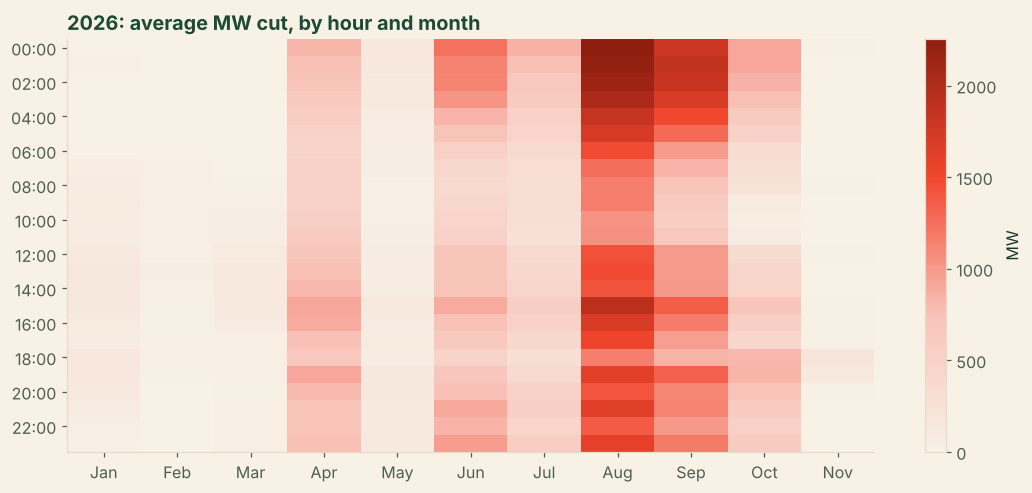

Worst month August (1,164 GWh). In Jun to Sep the deepest cuts came after midnight: 1,448 MW on average from 00:00 to 03:00 against 920 MW at the 18:00 to 22:00 evening peak.


In [3]:
hm = q("""SELECT month(ts) AS month, hour, avg(load_shed_mw) AS mw FROM gold.hourly
          WHERE year = 2026 GROUP BY ALL""").pivot(index='hour', columns='month', values='mw')
fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(hm.values, aspect='auto', cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list('t', ['#F7F1E6', '#F9C2B8', TOMATO, '#8E1F10']))
ax.set_yticks(range(0, 24, 2), [f'{h:02d}:00' for h in range(0, 24, 2)]); ax.set_xticks(range(len(hm.columns)), [pd.Timestamp(2026, m, 1).strftime('%b') for m in hm.columns])
ax.grid(False); ax.set_title('2026: average MW cut, by hour and month'); plt.colorbar(im, ax=ax, label='MW')
plt.tight_layout(); plt.show()
p = q("SELECT hour, avg_shed_mw FROM gold.hour_profile WHERE year = 2026 AND season = 'Monsoon (Jun to Sep)' ORDER BY hour")
night = p[p.hour.between(0, 3)].avg_shed_mw.mean(); eve = p[p.hour.between(18, 22)].avg_shed_mw.mean()
worst_m = q("SELECT strftime(month, '%B') AS m, energy_shed_gwh FROM gold.monthly WHERE year = 2026 ORDER BY 2 DESC LIMIT 1").iloc[0]
A[7] = (f"Worst month {worst_m.m} ({worst_m.energy_shed_gwh:,.0f} GWh). In Jun to Sep the deepest cuts came after midnight: "
        f"{night:,.0f} MW on average from 00:00 to 03:00 against {eve:,.0f} MW at the 18:00 to 22:00 evening peak.")
print(A[7])

## Q3. What breaks first?

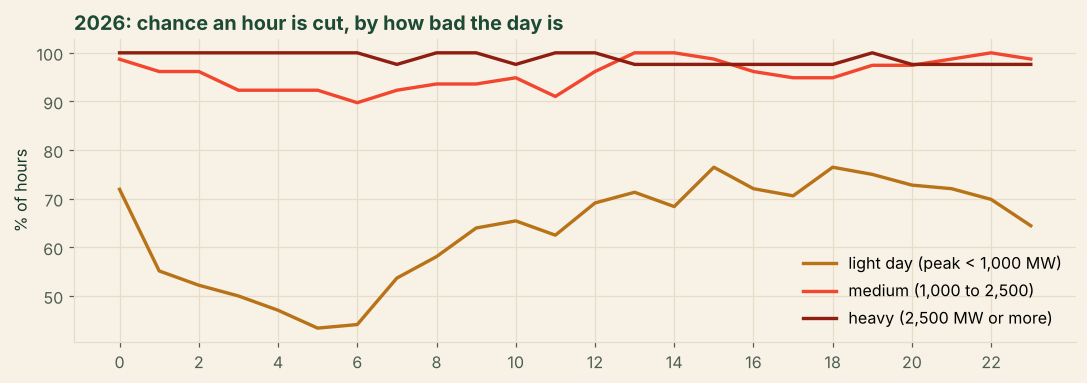

On light days the first hours to go are 18:00, 15:00, 19:00 (cut on 76% of light days at 18:00); on heavy days almost every hour is cut.


In [4]:
b = q("""WITH d AS (SELECT date, max(load_shed_mw) AS mx FROM gold.hourly WHERE year = 2026 GROUP BY date)
         SELECT CASE WHEN mx < 1000 THEN '1. light day (peak < 1,000 MW)' WHEN mx < 2500 THEN '2. medium (1,000 to 2,500)'
                     ELSE '3. heavy (2,500 MW or more)' END AS day_type, h.hour,
                avg(CASE WHEN load_shed_mw > 0 THEN 1.0 ELSE 0 END) AS p_cut
         FROM gold.hourly h JOIN d USING (date) WHERE h.year = 2026 AND d.mx > 0 GROUP BY ALL""")
pv = b.pivot(index='hour', columns='day_type', values='p_cut')
fig, ax = plt.subplots(figsize=(10, 3.6))
for c, col in zip(pv.columns, [OCHRE, TOMATO, '#8E1F10']): ax.plot(pv.index, pv[c] * 100, color=col, lw=2.2, label=c[3:])
ax.set_title('2026: chance an hour is cut, by how bad the day is'); ax.set_ylabel('% of hours'); ax.set_xticks(range(0, 24, 2))
ax.legend(frameon=False); plt.tight_layout(); plt.show()
light = pv.iloc[:, 0].sort_values(ascending=False)
A[3] = (f"On light days the first hours to go are {', '.join(f'{h:02d}:00' for h in light.index[:3])} "
        f"(cut on {light.iloc[0]:.0%} of light days at {light.index[0]:02d}:00); on heavy days almost every hour is cut.")
print(A[3])

## Q11. Why? August 2026 against August 2025

Average MW shed in August: 2025 11, 2026 1,534, change +1,523
Check: sum of steps +1,523 MW (should equal the change)



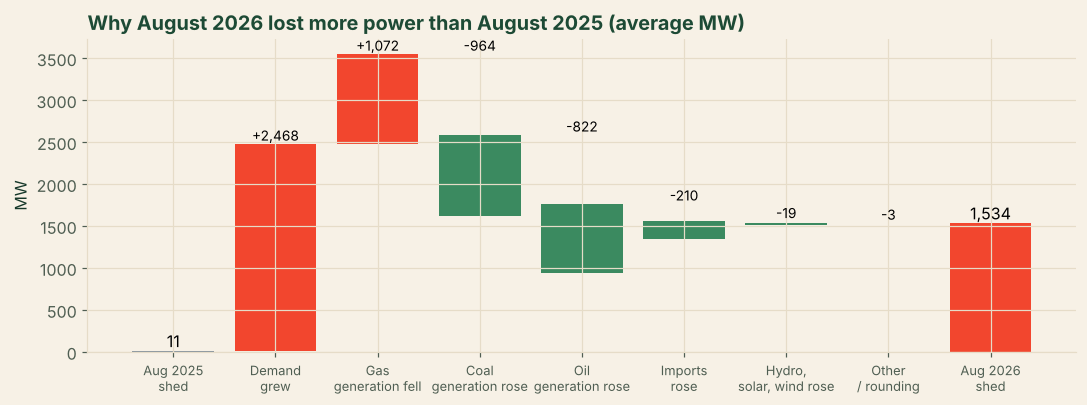

Demand grew                2468.0
Gas generation fell        1072.0
Coal generation rose       -964.0
Oil generation rose        -822.0
Imports rose               -210.0
Hydro, solar, wind rose     -19.0
Other / rounding             -3.0
August 2026 shed 1,523 MW more on average than August 2025. Pushing it up: demand grew (+2,468 MW); gas generation fell (+1,072 MW). Partly offset by: coal generation rose (-964 MW); oil generation rose (-822 MW); imports rose (-210 MW). The demand jump (about 18%) is checked against August temperatures in Phase 4 before it is quoted.

BPDB reported supply limits, June to July average (MW):
 year  gas_fuel_limit  coal_limit  maintenance
 2023          2048.0        81.0       1902.0
 2024          3041.0        52.0       2032.0
 2025          2610.0         0.0       2599.0
 2026          4072.0       111.0       1804.0


In [5]:
m = q("""SELECT year, avg(true_demand_mw) AS demand, avg(gas) AS gas, avg(coal) AS coal, avg(liquid_fuel) AS oil,
              avg(imports) AS imports, avg(coalesce(hydro,0)+coalesce(solar,0)+coalesce(wind,0)) AS renewables,
              avg(parts_gap_mw) AS other, avg(load_shed_mw) AS shed
         FROM gold.hourly WHERE month = 8 AND year IN (2025, 2026) AND hour >= 1 GROUP BY year ORDER BY year""").set_index('year')
d = m.loc[2026] - m.loc[2025]
# shed change = demand change - (sum of supply changes); supply falling raises the shortfall
raw = {'Gas generation': -d.gas, 'Coal generation': -d.coal, 'Oil generation': -d.oil, 'Imports': -d.imports,
       'Hydro, solar, wind': -d.renewables}
steps = pd.Series({('Demand grew' if d.demand > 0 else 'Demand fell'): d.demand,
                   **{f"{k} {'fell' if v > 0 else 'rose'}": v for k, v in raw.items()}, 'Other / rounding': -d.other})
print(f"Average MW shed in August: 2025 {m.loc[2025, 'shed']:,.0f}, 2026 {m.loc[2026, 'shed']:,.0f}, change {d.shed:+,.0f}")
print(f"Check: sum of steps {steps.sum():+,.0f} MW (should equal the change)\n")
fig, ax = plt.subplots(figsize=(10, 3.8)); run = m.loc[2025, 'shed']
ax.bar(0, run, color=SLATE); ax.text(0, run, f'{run:,.0f}', ha='center', va='bottom')
for i, (k, v) in enumerate(steps.items(), 1):
    ax.bar(i, v, bottom=run if v >= 0 else run + v, color=TOMATO if v > 0 else GREEN2)
    ax.text(i, max(run, run + v), f'{v:+,.0f}', ha='center', va='bottom', fontsize=9); run += v
ax.bar(len(steps) + 1, run, color=TOMATO); ax.text(len(steps) + 1, run, f'{run:,.0f}', ha='center', va='bottom')
ax.set_xticks(range(len(steps) + 2), ['Aug 2025\nshed'] + [s.replace(' ', '\n', 1) for s in steps.index] + ['Aug 2026\nshed'], fontsize=8.5)
ax.set_title('Why August 2026 lost more power than August 2025 (average MW)'); ax.set_ylabel('MW')
plt.tight_layout(); plt.show()
print(steps.round(0).to_string())
up = steps[(steps > 50)].sort_values(ascending=False); off = steps[(steps < -50)].sort_values()
A[11] = (f"August 2026 shed {d.shed:,.0f} MW more on average than August 2025. Pushing it up: "
         + '; '.join(f'{k.lower()} ({v:+,.0f} MW)' for k, v in up.items())
         + ('. Partly offset by: ' + '; '.join(f'{k.lower()} ({v:+,.0f} MW)' for k, v in off.items()) if len(off) else '')
         + '. The demand jump (about 18%) is checked against August temperatures in Phase 4 before it is quoted.')
print(A[11])
lim = q("""SELECT year(date) AS year, round(avg(limit_gas_fuel_mw)) AS gas_fuel_limit, round(avg(limit_coal_mw)) AS coal_limit,
           round(avg(plants_maintenance_mw)) AS maintenance FROM gold.daily WHERE month(date) BETWEEN 6 AND 7 AND year >= 2023
           GROUP BY 1 ORDER BY 1""")
print('\nBPDB reported supply limits, June to July average (MW):'); print(lim.to_string(index=False))

## Q2. How much is gas worth in power?
Our data has gas *generation* by hour but not the gas *supply* in million cubic feet, so MW per mmcfd needs
Petrobangla's daily gas allocation (to collect in Phase 4). For now: how load shed moves with gas generation.

In [6]:
g = q("""SELECT date, avg_gas_mw, energy_shed_mwh / 24 AS avg_shed_mw, max_true_demand_mw FROM gold.daily
         WHERE year = 2026 AND month(date) BETWEEN 6 AND 10""")
X = np.c_[np.ones(len(g)), g.avg_gas_mw, g.max_true_demand_mw]; coef = np.linalg.lstsq(X, g.avg_shed_mw, rcond=None)[0]
A[2] = (f"Jun to Oct 2026, at the same level of demand, every 100 MW less gas generation went with about "
        f"{-coef[1]*100:,.0f} MW more load shed on average. Converting to million cubic feet needs Petrobangla's gas data (Phase 4).")
print(A[2])

Jun to Oct 2026, at the same level of demand, every 100 MW less gas generation went with about 53 MW more load shed on average. Converting to million cubic feet needs Petrobangla's gas data (Phase 4).


## Q4. Fuel, storage or demand? Where the gap sits in the day

In [7]:
e = q("""SELECT sum(shed_daylight_mwh) AS daylight, sum(shed_evening_mwh) AS evening, sum(shed_night_mwh) AS night
         FROM gold.daily WHERE year = 2026""").iloc[0]
tot = e.sum(); share = e / tot
dd = q("SELECT date, coalesce(shed_evening_mwh,0) + coalesce(shed_night_mwh,0) AS after_dark_mwh, max_solar_mw FROM gold.daily WHERE year = 2026 AND energy_shed_mwh > 0")
p90 = dd.after_dark_mwh.quantile(.9); solar = q("SELECT max(max_solar_mw) AS s FROM gold.daily WHERE year = 2026").s.iloc[0]
A[4] = (f"{share.evening + share.night:.0%} of 2026's lost energy was after dark (18:00 to 06:59) and {share.daylight:.0%} in daylight. "
        f"Solar peaked at {solar:,.0f} MW, so more solar alone cannot reach most of the gap.")
print(A[4])

61% of 2026's lost energy was after dark (18:00 to 06:59) and 39% in daylight. Solar peaked at 796 MW, so more solar alone cannot reach most of the gap.


## Q5. Can cuts be forecast? (first look; Phase 3 builds the forecast)

In [8]:
s = q("SELECT date, max_shed_mw FROM gold.daily WHERE year = 2026 ORDER BY date").set_index('date').max_shed_mw
bad = s > 1500
p_next = (bad & bad.shift(1)).sum() / bad.shift(1).sum()
A[5] = (f"Bad days come in runs: in 2026, after a day with a peak cut above 1,500 MW, the next day was also above 1,500 MW "
        f"{p_next:.0%} of the time (74% across 2022 to 2026; lag-1 correlation of daily peaks {s.autocorr(1):.2f}). That persistence is what a 7-day outlook builds on.")
print(A[5])

Bad days come in runs: in 2026, after a day with a peak cut above 1,500 MW, the next day was also above 1,500 MW 85% of the time (74% across 2022 to 2026; lag-1 correlation of daily peaks 0.87). That persistence is what a 7-day outlook builds on.


## Q6. Who carries the cuts? (zones, daily BPDB data, evening peak)

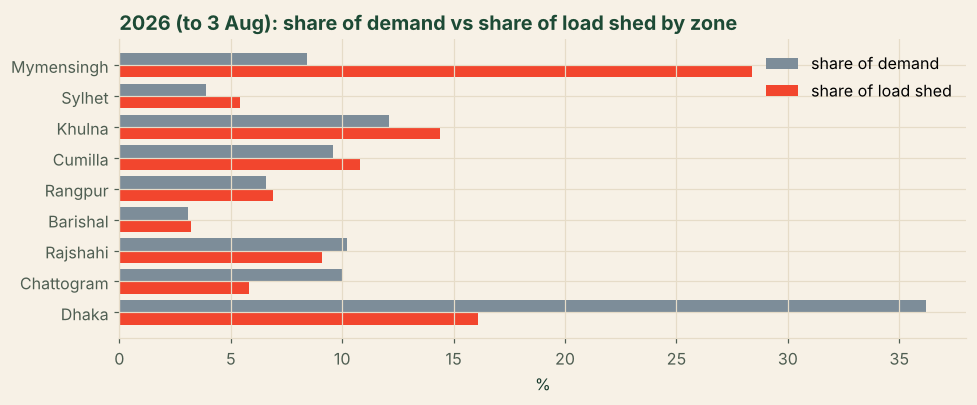

Mymensingh carried 28% of the load shed with 8% of the demand (3.4x its share); Dhaka 16% with 36% (0.4x). Mymensingh's ratio by year: 2022 2.8x, 2023 3.4x, 2024 3.7x, 2025 4.9x, 2026 3.4x.


,zone,pct_of_demand,pct_of_load_shed,burden_ratio,shed_as_pct_of_own_demand
0,Mymensingh,8.4,28.4,3.39,10.01
1,Sylhet,3.9,5.4,1.38,4.07
2,Khulna,12.1,14.4,1.19,3.51
3,Cumilla,9.6,10.8,1.13,3.33
4,Rangpur,6.6,6.9,1.05,3.10
5,Barishal,3.1,3.2,1.02,3.02
6,Rajshahi,10.2,9.1,0.90,2.64
7,Chattogram,10.0,5.8,0.58,1.72
8,Dhaka,36.2,16.1,0.44,1.31


In [9]:
z = q("SELECT zone, pct_of_demand, pct_of_load_shed, burden_ratio, shed_as_pct_of_own_demand FROM gold.zone_share WHERE year = 2026 ORDER BY burden_ratio DESC")
fig, ax = plt.subplots(figsize=(9, 3.8)); yy = np.arange(len(z))[::-1]
ax.barh(yy + .2, z.pct_of_demand, .4, color=SLATE, label='share of demand'); ax.barh(yy - .2, z.pct_of_load_shed, .4, color=TOMATO, label='share of load shed')
ax.set_yticks(yy, z.zone); ax.set_xlabel('%'); ax.legend(frameon=False); ax.set_title('2026 (to 3 Aug): share of demand vs share of load shed by zone')
plt.tight_layout(); plt.show()
my, dh = z.set_index('zone').loc['Mymensingh'], z.set_index('zone').loc['Dhaka']
hist = q("SELECT year, burden_ratio FROM gold.zone_share WHERE zone = 'Mymensingh' AND year >= 2022 ORDER BY year")
A[6] = (f"Mymensingh carried {my.pct_of_load_shed:.0f}% of the load shed with {my.pct_of_demand:.0f}% of the demand ({my.burden_ratio:.1f}x its share); "
        f"Dhaka {dh.pct_of_load_shed:.0f}% with {dh.pct_of_demand:.0f}% ({dh.burden_ratio:.1f}x). Mymensingh's ratio by year: "
        + ', '.join(f'{int(r.year)} {r.burden_ratio:.1f}x' for r in hist.itertuples()) + '.')
print(A[6]); z

## Q9. Which working hours are safest?

In [10]:
w = q("""SELECT season, window_name, pct_hours_with_shed, avg_shed_mw FROM gold.shift_windows
         WHERE year = 2026 ORDER BY season, avg_shed_mw""")
print(w.pivot(index='window_name', columns='season', values='avg_shed_mw').to_string())
mon = w[w.season == 'Monsoon (Jun to Sep)'].sort_values('avg_shed_mw')
A[9] = (f"In the 2026 monsoon every shift was hit almost daily; the lightest was {mon.iloc[0].window_name} "
        f"({mon.iloc[0].avg_shed_mw:,.0f} MW cut on average) and the heaviest {mon.iloc[-1].window_name} ({mon.iloc[-1].avg_shed_mw:,.0f} MW).")
print('\n' + A[9])

season                       Monsoon (Jun to Sep)  Post-monsoon (Oct to Nov)  Pre-monsoon (Mar to May)  Winter (Dec to Feb)
window_name                                                                                                                
Day shift 8 am to 8 pm                      827.0                      296.0                     280.0                 71.0
Early shift 6 am to 2 pm                    722.0                      164.0                     218.0                 56.0
Evening shift 2 pm to 10 pm                 960.0                      445.0                     321.0                 72.0
Night shift 10 pm to 6 am                  1210.0                      459.0                     259.0                  8.0
Office day 9 am to 5 pm                     837.0                      235.0                     286.0                 71.0

In the 2026 monsoon every shift was hit almost daily; the lightest was Early shift 6 am to 2 pm (722 MW cut on average) and the hea

## Q10. How much does heat add?

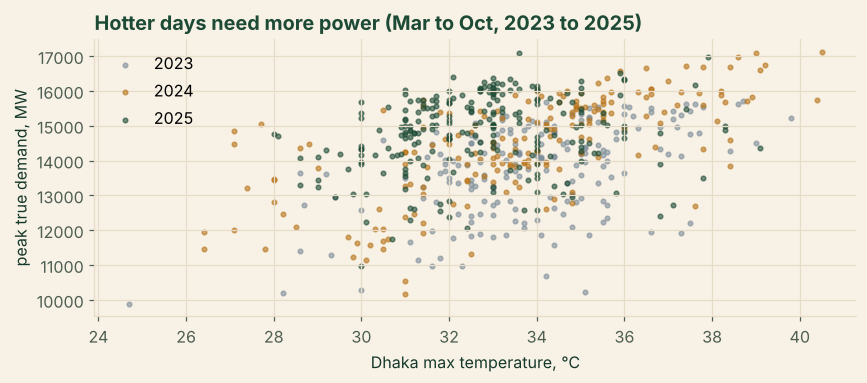

Each °C above 30°C in Dhaka added about 331 MW to the day's peak demand (2023 to 2025, same year and season).


In [11]:
h = q("""SELECT date, year, dhaka_max_temp_c AS t, max_true_demand_mw AS dmax FROM gold.daily
         WHERE year BETWEEN 2023 AND 2025 AND month(date) BETWEEN 3 AND 10 AND dhaka_max_temp_c BETWEEN 20 AND 45
           AND date NOT IN (SELECT date FROM silver.holidays)""").dropna()
h['over30'] = (h.t - 30).clip(lower=0)
X = np.c_[np.ones(len(h)), h.over30, *(h.year == y_ for y_ in [2024, 2025]), pd.to_datetime(h.date).dt.dayofyear]
b = np.linalg.lstsq(X.astype(float), h.dmax, rcond=None)[0]
fig, ax = plt.subplots(figsize=(8, 3.6))
for y_, c in [(2023, SLATE), (2024, OCHRE), (2025, GREEN)]:
    s_ = h[h.year == y_]; ax.scatter(s_.t, s_.dmax, s=9, color=c, alpha=.6, label=str(y_))
ax.set_xlabel('Dhaka max temperature, °C'); ax.set_ylabel('peak true demand, MW'); ax.legend(frameon=False)
ax.set_title('Hotter days need more power (Mar to Oct, 2023 to 2025)'); plt.tight_layout(); plt.show()
A[10] = f"Each °C above 30°C in Dhaka added about {b[1]:,.0f} MW to the day's peak demand (2023 to 2025, same year and season)."
print(A[10])

## Q1. Did the saving rules work?

Placebo days: 203; 90% of random 7-day swings are within ±614 MW

 rule_date  closing_hour  evening_change_mw  beyond_noise
2026-04-02            20             -440.0         False
2026-04-03            18             -246.0         False
2026-04-05            19             -217.0         False
2026-05-12            22               75.0         False
2026-06-01            19             -164.0         False
2026-06-11            21              524.0         False
2026-08-13            20              194.0         False


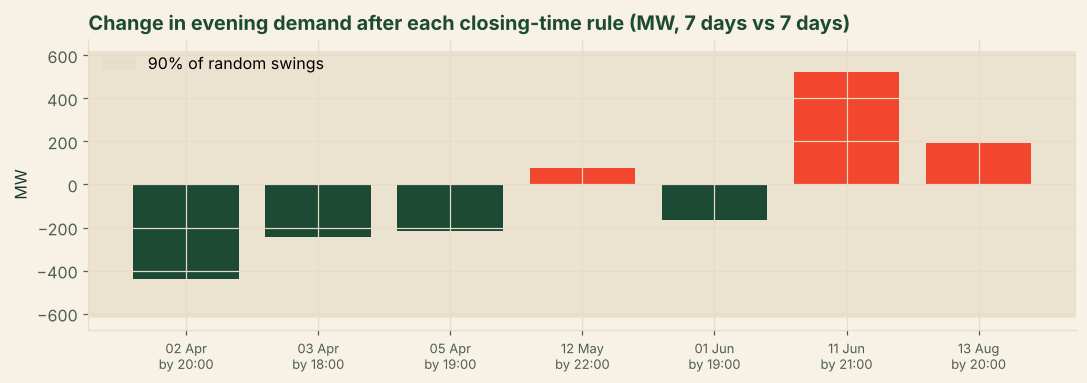

 rule_date            kind  evening_change_mw  as_expected  beyond_noise
2026-04-02 earlier closing             -440.0         True         False
2026-05-12   later closing               75.0         True         False
2026-06-01 earlier closing             -164.0         True         False
2026-06-11   later closing              524.0         True         False
2026-08-13 earlier closing              194.0        False         False

Probably a little, not proven. In 4 of 5 rule changes evening demand moved the expected way (April package -440 MW, 1 June -164 MW; relaxing on 11 June +524 MW), but none is larger than ordinary week-to-week swings (±614 MW), and 13 August showed no drop. Phase 4 tests this with hourly weather.


In [12]:
pc = q("SELECT rule_date, event, closing_hour, ratio_before, ratio_after, evening_change_mw FROM gold.policy_check")
# Placebo: the same 7-day before/after test on every 2026 day with no rule nearby, to see how big random swings are
r = q("""SELECT date, avg(true_demand_mw) FILTER (WHERE hour BETWEEN 19 AND 22) / avg(true_demand_mw) FILTER (WHERE hour BETWEEN 14 AND 17) AS ratio,
                avg(true_demand_mw) FILTER (WHERE hour BETWEEN 14 AND 17) AS aft
         FROM gold.hourly WHERE year = 2026 AND date NOT IN (SELECT date FROM silver.holidays) GROUP BY date ORDER BY date""")
r['date'] = pd.to_datetime(r.date); rd = pd.to_datetime(pc.rule_date)
plac = []
for i in range(7, len(r) - 7):
    t = r.date.iloc[i]
    if (abs((rd - t).dt.days) <= 10).any(): continue
    plac.append((r.ratio.iloc[i+1:i+8].mean() - r.ratio.iloc[i-7:i].mean()) * r.aft.iloc[i+1:i+8].mean())
plac = pd.Series(plac); band = plac.abs().quantile(.9)
pc['beyond_noise'] = pc.evening_change_mw.abs() > band
print(f'Placebo days: {len(plac)}; 90% of random 7-day swings are within ±{band:,.0f} MW\n')
print(pc[['rule_date', 'closing_hour', 'evening_change_mw', 'beyond_noise']].to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axhspan(-band, band, color=GRID, alpha=.7, label='90% of random swings')
col = [GREEN if v < 0 else TOMATO for v in pc.evening_change_mw]
ax.bar(range(len(pc)), pc.evening_change_mw, color=col)
ax.set_xticks(range(len(pc)), [f"{pd.Timestamp(d):%d %b}\n{'by %d:00' % h}" for d, h in zip(pc.rule_date, pc.closing_hour)], fontsize=8.5)
ax.set_title('Change in evening demand after each closing-time rule (MW, 7 days vs 7 days)'); ax.set_ylabel('MW'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
apr = pc[pc.rule_date.astype(str) == '2026-04-02'].evening_change_mw.iloc[0]
jun11 = pc[pc.rule_date.astype(str) == '2026-06-11'].evening_change_mw.iloc[0]
# Treat the three early-April steps as one package (their windows overlap)
ind = pc[~pc.rule_date.astype(str).isin(['2026-04-03', '2026-04-05'])].copy()
ind['kind'] = np.where(ind.rule_date.astype(str).isin(['2026-05-12', '2026-06-11']), 'later closing', 'earlier closing')
ind['as_expected'] = np.where(ind.kind == 'earlier closing', ind.evening_change_mw < 0, ind.evening_change_mw > 0)
print(ind[['rule_date', 'kind', 'evening_change_mw', 'as_expected', 'beyond_noise']].to_string(index=False))
n_ok, n = int(ind.as_expected.sum()), len(ind)
A[1] = (f"Probably a little, not proven. In {n_ok} of {n} rule changes evening demand moved the expected way "
        f"(April package {apr:+,.0f} MW, 1 June {pc.iloc[4].evening_change_mw:+,.0f} MW; relaxing on 11 June {jun11:+,.0f} MW), "
        f"but none is larger than ordinary week-to-week swings (±{band:,.0f} MW), and 13 August showed no drop. "
        f"Phase 4 tests this with hourly weather.")
print('\n' + A[1])

## Q8 and the forecast
Q8 (expected MW cut per hour for the next 7 days) is Phase 3: baselines, the model, and the scorecard.

In [13]:
A[8] = 'Phase 3: the 7-day hourly forecast and its scorecard.' 

## The 12 answers so far

In [14]:
labels = {1: 'Did the saving rules work?', 2: 'How much is gas worth in power?', 3: 'What breaks first?',
          4: 'Fuel, storage or demand?', 5: 'Can cuts be forecast?', 6: 'Who carries the cuts?', 7: 'When does it hit?',
          8: 'How much next week?', 9: 'Which shifts are safest?', 10: 'How much does heat add?', 11: 'Why?', 12: 'How bad is 2026?'}
for k in sorted(A): print(f'Q{k}. {labels[k]}\n    {A[k]}\n')

Q1. Did the saving rules work?
    Probably a little, not proven. In 4 of 5 rule changes evening demand moved the expected way (April package -440 MW, 1 June -164 MW; relaxing on 11 June +524 MW), but none is larger than ordinary week-to-week swings (±614 MW), and 13 August showed no drop. Phase 4 tests this with hourly weather.

Q2. How much is gas worth in power?
    Jun to Oct 2026, at the same level of demand, every 100 MW less gas generation went with about 53 MW more load shed on average. Converting to million cubic feet needs Petrobangla's gas data (Phase 4).

Q3. What breaks first?
    On light days the first hours to go are 18:00, 15:00, 19:00 (cut on 76% of light days at 18:00); on heavy days almost every hour is cut.

Q4. Fuel, storage or demand?
    61% of 2026's lost energy was after dark (18:00 to 06:59) and 39% in daylight. Solar peaked at 796 MW, so more solar alone cannot reach most of the gap.

Q5. Can cuts be forecast?
    Bad days come in runs: in 2026, after a day 